In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

# For saving the state of the graph to memory, stores the memory in the RAM.
from langgraph.checkpoint.memory import MemorySaver

In [2]:
load_dotenv()

True

In [3]:
llm = ChatOpenAI()

In [4]:
from langgraph.graph.message import add_messages

# State is something that is passed to the graph and 
# can be used to store information about the current state of the conversation.


class ChatState(TypedDict): 
    messages: Annotated[list[BaseMessage], add_messages] # Using reducer for 'messages' to add 'messages' to the state.

In [5]:
# Creating chat node function that takes the state as 
# input and returns the updated state with the response from the LLM.

def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}

In [6]:
graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node) # Only one node is required for this simple chatbot.

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

# Compile the graph.
chatbot = graph.compile()

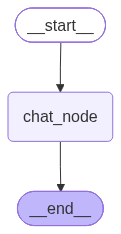

In [7]:
chatbot

In [8]:
initial_state = {
    'messages': [HumanMessage(content='What is OOPs in python?')]
}

response = chatbot.invoke(initial_state)

NotFoundError: Error code: 404 - {'error': {'message': 'The model `gpt-3.5-turbo` has been deprecated, learn more here: https://platform.openai.com/docs/deprecations', 'type': 'invalid_request_error', 'param': None, 'code': 'model_not_found'}}

In [ ]:
response['messages'][-1].content

'OOPs stands for Object-Oriented Programming. It is a programming paradigm that uses objects and classes to organize code and data. In Python, OOPs allows you to create classes and objects, encapsulate data and behavior within objects, and define relationships between objects. OOPs in Python includes concepts such as inheritance, polymorphism, encapsulation, and abstraction. It helps in writing reusable and modular code, making it easier to maintain and scale applications.'

In [14]:
while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]})
    print('AI:', response['messages'][-1].content)

User: Hi
AI: Hello! How can I assist you today?
User: My name is Arpan
AI: Hello Arpan, nice to meet you! How can I assist you today?
User: Tell me about Python
AI: Python is a high-level, versatile programming language that is known for its simplicity and readability. It was created in the late 1980s by Guido van Rossum and has since become one of the most popular programming languages in the world.

Some key features of Python include its easy-to-read syntax, dynamic typing, and automatic memory management. It supports multiple programming paradigms including procedural, object-oriented, and functional programming.

Python has a large standard library that provides built-in modules and functions for tasks such as file I/O, networking, and data processing. In addition, there is a vast ecosystem of third-party libraries and frameworks that extend the capabilities of Python for web development, data science, machine learning, and more.

Python is often used for a wide range of applicati

## Still it cannot give me my info as I have shared my name before in the conversation, cause Persistent memory is not implemented yet. So, I will implement it in the next step.

In [15]:
checkpoint = MemorySaver() # Persistence of the state of the graph to memory, stores the memory in the RAM.

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node) # Only one node is required for this simple chatbot.

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

# Compile the graph.
chatbot = graph.compile(checkpointer=checkpoint) # Compile the graph with the checkpoint to save the state of the graph to memory.

In [16]:
thread_id = "1"

while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break
    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

User: Hi, my name is Arpan
AI: Hello Arpan, how can I assist you today?
User: tell me 5 wild animals name
AI: 1. Tiger
2. Lion
3. Elephant
4. Giraffe
5. Cheetah
User: what is my name ?
AI: Your name is Arpan.
User: oh you remember my name ?
AI: Yes, I have the ability to remember names and other information that is shared with me during a conversation. How can I assist you further, Arpan?
User: thank u
AI: You're welcome! If you have any more questions or need assistance in the future, feel free to ask. Have a great day, Arpan!
User: bye


In [ ]:
chatbot.get_state(config=config)